# 02 · Shack–Hartmann sensing and modal reconstruction

A Shack–Hartmann sensor splits the pupil into sub-apertures with a lenslet array. Each lenslet forms a spot, and the spot moves in proportion to the average phase gradient across its sub-aperture. This notebook uses the geometric model in `reconstruction.py`: average slopes per sub-aperture, a response matrix for Zernike modes, and least-squares reconstruction.

**Checks against theory:** a pure tilt is measured exactly in every sub-aperture; a wavefront built from modes in the basis is recovered exactly; and the residual after correcting the first J Zernike modes follows Noll's table.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIGURES = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from phase_screen import fourier_phase_screen
from reconstruction import build_response_matrix, measure_slopes, residual_wavefront, rms, subaperture_masks
from zernike import generate_zernike_modes, make_pupil_grid, synthesize_wavefront, zernike_named_modes

## 1. Lenslet geometry

The pupil is cut into a 10 × 10 grid; a sub-aperture is used when at least half of it is illuminated. Each one returns two numbers, the average x and y slope, so the measurement vector has twice as many entries as there are valid sub-apertures.

80 valid sub-apertures of 10 cm -> 160 slope measurements


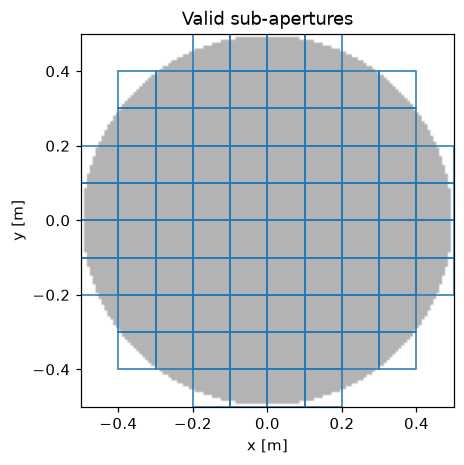

In [2]:
D = 1.0
N = 128
N_LENSLETS = 10
MIN_FILL = 0.5

X, Y, rho, theta, pupil, dx = make_pupil_grid(N=N, diameter=D)
centers, masks = subaperture_masks(X, Y, pupil, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
size = D / N_LENSLETS
print(f"{len(masks)} valid sub-apertures of {size * 100:.0f} cm -> {2 * len(masks)} slope measurements")

fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.imshow(pupil, origin="lower", cmap="Greys", alpha=0.3, extent=[-D / 2, D / 2, -D / 2, D / 2])
for cx, cy in centers:
    ax.add_patch(plt.Rectangle((cx - size / 2, cy - size / 2), size, size, fill=False, color="C0", lw=1))
ax.set(title="Valid sub-apertures", xlabel="x [m]", ylabel="y [m]")
ax.grid(False)
plt.show()

## 2. Slopes

The slope of a sub-aperture is the mean of the phase gradient over its illuminated pixels. Samples outside the pupil are NaN, so a finite difference that would reach outside the pupil is dropped instead of seeing a jump to zero; that is what makes the edge sub-apertures correct.

Tilt check: largest slope error over 80 sub-apertures = 1.8e-15 rad/m


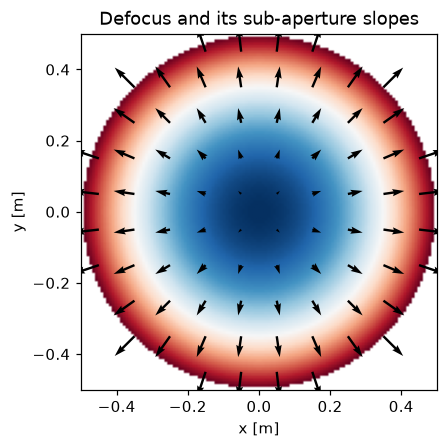

In [3]:
tilt = np.where(pupil, 0.7 * X - 0.3 * Y, np.nan)        # rad, slopes 0.7 and -0.3 rad/m
_, slopes = measure_slopes(tilt, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
print(f"Tilt check: largest slope error over {len(slopes)} sub-apertures = {np.max(np.abs(slopes - [0.7, -0.3])):.1e} rad/m")

defocus = zernike_named_modes(rho, theta, pupil)["defocus"]
_, slopes = measure_slopes(defocus, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.imshow(defocus, origin="lower", cmap="RdBu_r", extent=[-D / 2, D / 2, -D / 2, D / 2])
ax.quiver(centers[:, 0], centers[:, 1], slopes[:, 0], slopes[:, 1], color="k")
ax.set(title="Defocus and its sub-aperture slopes", xlabel="x [m]", ylabel="y [m]")
ax.grid(False)
plt.show()

## 3. Response matrix and exact recovery

Poking each Zernike mode with unit amplitude gives one column of the response matrix $A$, so that the slopes of any combination of modes are $\mathbf{s} = A\mathbf{a}$. Least squares inverts it: $\hat{\mathbf{a}} = A^{+}\mathbf{s}$. A wavefront built from modes in the basis must come back exactly.

In [4]:
MAX_ORDER = 6
modes = generate_zernike_modes(rho, theta, pupil, max_radial_order=MAX_ORDER)
A, names, _ = build_response_matrix(modes, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
singular_values = np.linalg.svd(A, compute_uv=False)
print(f"{len(names)} modes up to radial order {MAX_ORDER}: response matrix {A.shape}, "
      f"rank {np.linalg.matrix_rank(A)}, condition number {singular_values[0] / singular_values[-1]:.1f}")

rng = np.random.default_rng(0)
true_coeffs = dict(zip(names[:14], rng.normal(scale=0.2, size=14)))
wavefront = synthesize_wavefront(modes, true_coeffs, pupil)
_, slopes = measure_slopes(wavefront, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
estimate, *_ = np.linalg.lstsq(A, slopes.reshape(-1), rcond=None)
reconstructed = synthesize_wavefront(modes, dict(zip(names, estimate)), pupil)
print(f"Input RMS {rms(wavefront, pupil):.3f} rad, residual after reconstruction {rms(residual_wavefront(wavefront, reconstructed, pupil), pupil):.1e} rad")

27 modes up to radial order 6: response matrix (160, 27), rank 27, condition number 8.4
Input RMS 0.671 rad, residual after reconstruction 1.9e-15 rad


## 4. Check: correcting J modes of Kolmogorov turbulence

Noll (1976) computed the phase variance left after removing the first $J$ Zernike modes (piston included) from Kolmogorov turbulence, $\Delta_J\,(D/r_0)^{5/3}$; for large $J$, $\Delta_J \approx 0.2944\,J^{-\sqrt{3}/2}$. Two estimates are compared with his values, averaged over 30 screens with $D/r_0 = 10$:

- **projection:** the best least-squares fit of the screen with the modes, which is what Noll's numbers describe;
- **Shack–Hartmann:** the modes reconstructed from the measured slopes, which also suffers from aliasing, because modes outside the basis leak into the slopes of modes inside it.

 J   Noll Delta_J   projection   Shack-Hartmann
 3       0.1340       0.1314         0.1468
 6       0.0648       0.0661         0.0885
10       0.0401       0.0406         0.0514
15       0.0279       0.0285         0.0340
21       0.0208       0.0216         0.0247
28       0.0164       0.0171         0.0196


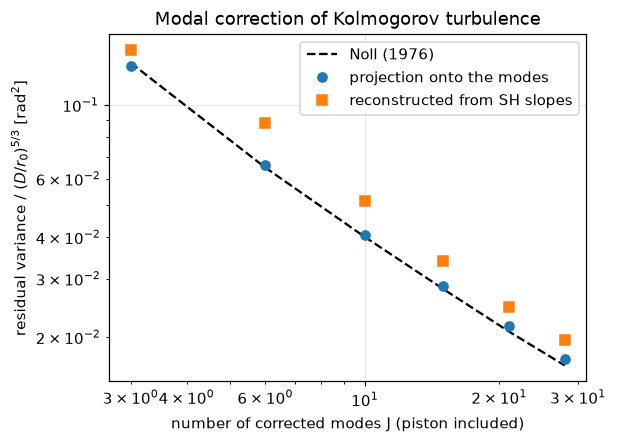

In [5]:
R0 = 0.1                                    # D/r0 = 10, Kolmogorov
NOLL = {3: 0.134, 6: 0.0648, 10: 0.0401, 15: 0.0279, 21: 0.0208, 28: 0.2944 * 28 ** (-np.sqrt(3) / 2)}
orders = range(1, MAX_ORDER + 1)
J_values = [(n + 1) * (n + 2) // 2 for n in orders]

basis = np.column_stack([np.ones(pupil.sum())] + [modes[name][pupil] for name in names])
projection = np.zeros(len(J_values))
shack_hartmann = np.zeros(len(J_values))
N_SCREENS = 30
for seed in range(N_SCREENS):
    sheet, *_ = fourier_phase_screen(N=N, delta=dx, r0=R0, L0=None, diameter=None, seed=seed)
    screen = np.where(pupil, sheet - np.mean(sheet[pupil]), np.nan)
    _, slopes = measure_slopes(screen, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
    for i, J in enumerate(J_values):
        fit, *_ = np.linalg.lstsq(basis[:, :J], screen[pupil], rcond=None)
        projection[i] += np.var(screen[pupil] - basis[:, :J] @ fit)
        estimate, *_ = np.linalg.lstsq(A[:, : J - 1], slopes.reshape(-1), rcond=None)
        residual = screen[pupil] - basis[:, 1:J] @ estimate
        shack_hartmann[i] += np.var(residual)
scale = (D / R0) ** (5 / 3)
projection /= N_SCREENS * scale
shack_hartmann /= N_SCREENS * scale

print(" J   Noll Delta_J   projection   Shack-Hartmann")
for J, p, s in zip(J_values, projection, shack_hartmann):
    print(f"{J:2d}   {NOLL[J]:10.4f}   {p:10.4f}   {s:12.4f}")

fig, ax = plt.subplots(figsize=(5.6, 4.1))
ax.loglog(J_values, [NOLL[J] for J in J_values], "k--", label="Noll (1976)")
ax.loglog(J_values, projection, "o", label="projection onto the modes")
ax.loglog(J_values, shack_hartmann, "s", label="reconstructed from SH slopes")
ax.set(xlabel="number of corrected modes J (piston included)", ylabel=r"residual variance / $(D/r_0)^{5/3}$ [rad$^2$]",
       title="Modal correction of Kolmogorov turbulence")
ax.legend()
fig.savefig(FIGURES / "02_noll_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

- 80 sub-apertures give 160 slopes. A pure tilt is measured to 1e-15 rad/m in every one, and a wavefront built from 14 modes is recovered to 1e-15 rad.
- The best fit with the first $J$ Zernike modes leaves Noll's $\Delta_J\,(D/r_0)^{5/3}$ to within 4% for $J$ = 3 to 28, which also confirms the screens of notebook 01.
- Reconstructing the same modes from slopes leaves 12–34% more variance. That is aliasing: structure outside the basis changes the slopes and is mistaken for modes inside it. Even for tip/tilt, the sensor measures the average gradient (G-tilt), not the best-fit tilt (Z-tilt).